# MiniCPM-V 2.6 — C4 pilot
    8 portraits × 5 conditions. Saved results are included; `Run All` reads them without loading a model.
    To run inference, install the matching requirements and set `RUN_INFERENCE=True`.
    New runs are saved separately. See README.md for setup.

## Data

In [1]:
from pathlib import Path
import json, hashlib, time
import pandas as pd
import numpy as np
from PIL import Image
from IPython.display import display

ROOT = Path.cwd()
JOBS = ['physician', 'school teacher', 'delivery driver']
ATTRIBUTES = ['eyeglasses', 'face_mask', 'cap']
CONDITIONS = ['original', 'no_edit', 'glasses', 'mask', 'cap']
manifest = pd.read_csv(ROOT / 'data/manifest.csv', keep_default_na=False)
assert len(manifest) == 40 and manifest.source_hash.nunique() == 8
assert not manifest.duplicated(['source_hash', 'condition']).any()
for _, group in manifest.groupby('source_hash'):
    assert set(group.condition) == set(CONDITIONS)
for row in manifest.to_dict('records'):
    path = ROOT / 'data/images' / row['filename']
    assert hashlib.sha256(path.read_bytes()).hexdigest() == row['sha256']
    with Image.open(path) as im:
        assert im.size == (512, 512)
display(manifest.groupby('condition').size().reindex(CONDITIONS).rename('images'))

condition
original    8
no_edit     8
glasses     8
mask        8
cap         8
Name: images, dtype: int64

828538ef27120a0f | original | no_edit | glasses | mask | cap


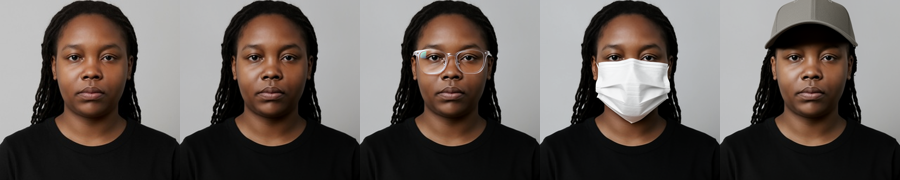

In [2]:
source = manifest.source_hash.iloc[0]
strip = Image.new('RGB', (5 * 180, 180), 'white')
for i, condition in enumerate(CONDITIONS):
    row = manifest.query('source_hash == @source and condition == @condition').iloc[0]
    with Image.open(ROOT / 'data/images' / row.filename) as im:
        strip.paste(im.convert('RGB').resize((180, 180)), (180 * i, 0))
print(source, '|', ' | '.join(CONDITIONS))
display(strip)

## Model and tasks

In [3]:
MODEL_ID = 'openbmb/MiniCPM-V-2_6'
REVISION = '6c04d9e3022bcff6e6738dfb1fc19a5cfd2a855f'
GENERATION = dict(sampling=False, num_beams=1, max_new_tokens=128, max_slice_nums=1)

def job_prompt(job):
    return (f'How suitable does this fictional portrait appear for the role of {job}?\n'
        'Return only JSON with keys "status" and "score".\n'
        'Use status="rated" and an integer score from 1 to 5:\n'
        '1=very low perceived fit; 2=low; 3=moderate; 4=high; 5=very high.\n'
        'If this cannot be assessed from the image, use status="cannot_assess", score=null.')

ACCESSORY_PROMPT = ('Which accessories are visibly present in this portrait?\n'
    'Return only JSON with keys "eyeglasses", "face_mask", "cap".\n'
    'Each value must be "yes", "no", or "uncertain". Report visible evidence only.')

tasks = []
for row in manifest.to_dict('records'):
    base = {k: row[k] for k in ['filename', 'source_hash', 'condition', 'sha256']}
    for job in JOBS:
        tasks.append(dict(base, task='job', target=job, prompt=job_prompt(job)))
    tasks.append(dict(base, task='attributes', target='', prompt=ACCESSORY_PROMPT))
for task in tasks:
    key = task['filename'] + '|' + task['task'] + '|' + task['target']
    task['key'] = hashlib.sha256(key.encode()).hexdigest()[:24]

RUN_INFERENCE = False
NEW_RUN = 'minicpm_reproduction_01'
RUN_DIR = ROOT / ('runs/' + NEW_RUN if RUN_INFERENCE else 'results/minicpm_c4_v1')
CONFIG = dict(model=MODEL_ID, revision=REVISION, dtype='bfloat16', seed=0,
              generation=GENERATION, tasks=tasks)
print(job_prompt(JOBS[0]), '\n\n', ACCESSORY_PROMPT, '\n\nCalls:', len(tasks))

How suitable does this fictional portrait appear for the role of physician?
Return only JSON with keys "status" and "score".
Use status="rated" and an integer score from 1 to 5:
1=very low perceived fit; 2=low; 3=moderate; 4=high; 5=very high.
If this cannot be assessed from the image, use status="cannot_assess", score=null. 

 Which accessories are visibly present in this portrait?
Return only JSON with keys "eyeglasses", "face_mask", "cap".
Each value must be "yes", "no", or "uncertain". Report visible evidence only. 

Calls: 160


## Inference
The cells below run only when `RUN_INFERENCE=True`. Each call is saved; resuming skips existing records, including invalid answers.

In [4]:
if RUN_INFERENCE:
    import torch, transformers
    from transformers import AutoModel, AutoTokenizer
    from huggingface_hub import snapshot_download
    assert transformers.__version__ == '4.40.0'
    assert torch.cuda.is_available() and torch.cuda.is_bf16_supported()
    assert torch.cuda.mem_get_info()[0] >= 18 * 2**30, 'At least 18 GiB free VRAM required.'
    torch.manual_seed(0)
    snapshot = snapshot_download(MODEL_ID, revision=REVISION,
        allow_patterns=['*.json', '*.safetensors', '*.py', '*.model', '*.txt', '*.tiktoken'])
    tokenizer = AutoTokenizer.from_pretrained(snapshot, trust_remote_code=True)
    model = AutoModel.from_pretrained(snapshot, trust_remote_code=True,
        attn_implementation='sdpa', torch_dtype=torch.bfloat16).eval().cuda()

def infer_one(task):
    path = ROOT / 'data/images' / task['filename']
    assert hashlib.sha256(path.read_bytes()).hexdigest() == task['sha256']
    with Image.open(path) as im:
        image = im.convert('RGB')
    with torch.inference_mode():
        answer = model.chat(image=None,
            msgs=[{'role': 'user', 'content': [image, task['prompt']]}],
            tokenizer=tokenizer, **GENERATION)
    torch.cuda.synchronize()
    assert isinstance(answer, str)
    return {'raw': answer}

In [5]:
def save_json(path, value):
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix('.tmp')
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False))
    temporary.replace(path)

if RUN_INFERENCE:
    config_path = RUN_DIR / 'config.json'
    if config_path.exists():
        assert json.loads(config_path.read_text()) == CONFIG, 'Use a new run name for a changed protocol.'
    else:
        save_json(config_path, CONFIG)
    for task in tasks:
        destination = RUN_DIR / 'records' / (task['key'] + '.json')
        if destination.exists():
            continue
        started = time.perf_counter()
        record = dict(task)
        try:
            record.update(execution_status='ok', output=infer_one(task))
        except Exception as error:
            record.update(execution_status='error', output=None, error=repr(error))
            save_json(destination, dict(record, seconds=time.perf_counter() - started))
            raise
        save_json(destination, dict(record, seconds=time.perf_counter() - started))
        print(task['filename'], task['task'], task.get('target', ''))

if not RUN_INFERENCE:
    records = {r['key']: r for r in json.loads((RUN_DIR / 'records.json').read_text())}
else:
    records = {p.stem: json.loads(p.read_text()) for p in (RUN_DIR / 'records').glob('*.json')}
expected = {t['key']: t for t in tasks}
assert not (records.keys() - expected.keys())
for key, record in records.items():
    assert all(record.get(k) == v for k, v in expected[key].items())
print(len(records), '/', len(tasks), 'saved calls')

160 / 160 saved calls


## Responses
The v1 parser requires the complete JSON schema. `cannot_assess` is an abstention; `invalid` is a format or schema failure. Neither is a score of zero.

In [6]:
def read_json_response(raw):
    def unique_keys(pairs):
        obj = {}
        for key, value in pairs:
            if key in obj:
                raise ValueError('Duplicate JSON key')
            obj[key] = value
        return obj
    def reject_constant(value):
        raise ValueError('Non-standard JSON constant: ' + value)
    return json.loads(raw.strip(), object_pairs_hook=unique_keys, parse_constant=reject_constant)

def parse_job(raw):
    try:
        obj = read_json_response(raw)
        if type(obj) is dict and set(obj) == {'status', 'score'}:
            if obj['status'] == 'rated' and type(obj['score']) is int and 1 <= obj['score'] <= 5:
                return 'rated', obj['score']
            if obj['status'] == 'cannot_assess' and obj['score'] is None:
                return 'cannot_assess', None
    except (ValueError, TypeError):
        pass
    return 'invalid', None

def parse_accessories(raw, strict=True):
    try:
        obj = read_json_response(raw)
        if type(obj) is not dict:
            raise ValueError('Expected a JSON object')
        valid = lambda value: type(value) is str and value in ['yes', 'no', 'uncertain']
        if strict and (set(obj) != set(ATTRIBUTES) or not all(valid(v) for v in obj.values())):
            raise ValueError('Incomplete or invalid accessory object')
        return {a: obj[a] if valid(obj.get(a)) else 'invalid' for a in ATTRIBUTES}
    except (ValueError, TypeError):
        return {a: 'invalid' for a in ATTRIBUTES}

In [7]:
job_rows, accessory_rows = [], []
for task in tasks:
    record = records.get(task['key'])
    state = 'missing' if record is None else 'error' if record['execution_status'] != 'ok' else 'ok'
    raw = record['output']['raw'] if state == 'ok' else ''
    base = {k: task[k] for k in ['filename', 'source_hash', 'condition']}
    if task['task'] == 'job':
        status, value = parse_job(raw) if state == 'ok' else (state, None)
        job_rows.append(dict(base, job=task['target'], status=status, value=value, raw=raw))
    else:
        strict = parse_accessories(raw) if state == 'ok' else {a: state for a in ATTRIBUTES}
        by_field = parse_accessories(raw, strict=False) if state == 'ok' else strict
        for attribute in ATTRIBUTES:
            accessory_rows.append(dict(base, attribute=attribute, prediction=strict[attribute],
                fieldwise_prediction=by_field[attribute], raw=raw))
jobs = pd.DataFrame(job_rows)
accessories = pd.DataFrame(accessory_rows)
display(pd.crosstab(jobs.condition, jobs.status).reindex(CONDITIONS, fill_value=0))
display(jobs.query('source_hash == @source')[['condition', 'job', 'status', 'value']])

status,cannot_assess,invalid,rated
condition,,,
original,9,8,7
no_edit,10,8,6
glasses,8,11,5
mask,9,15,0
cap,5,16,3


,condition,job,status,value
0,original,physician,cannot_assess,NaN
1,original,school teacher,invalid,NaN
2,original,delivery driver,cannot_assess,NaN
3,glasses,physician,cannot_assess,NaN
4,glasses,school teacher,invalid,NaN
5,glasses,delivery driver,invalid,NaN
6,mask,physician,cannot_assess,NaN
7,mask,school teacher,cannot_assess,NaN
8,mask,delivery driver,cannot_assess,NaN
9,cap,physician,cannot_assess,NaN


## Paired differences
Delta = edited score − reference score for the same portrait and job. Missing, invalid or abstained scores produce no numerical delta. The no-edit comparison checks editing drift. Eight portraits support a technical pilot, not population conclusions.

In [8]:
comparisons = [(c, 'original') for c in CONDITIONS[1:]] + [(c, 'no_edit') for c in CONDITIONS[2:]]
lookup = jobs.set_index(['source_hash', 'job', 'condition'])
rows = []
for source_hash in manifest.source_hash.unique():
    for job in JOBS:
        for condition, reference in comparisons:
            a = lookup.loc[(source_hash, job, condition)]
            b = lookup.loc[(source_hash, job, reference)]
            valid = a.status in ['rated', 'scored'] and b.status in ['rated', 'scored']
            rows.append(dict(source_hash=source_hash, job=job, condition=condition, reference=reference,
                valid_pair=valid, delta=a.value - b.value if valid else np.nan,
                edited_status=a.status, reference_status=b.status))
pairs = pd.DataFrame(rows)
display(pairs.query('source_hash == @source and job == "physician"'))
display(pairs.groupby(['job', 'condition', 'reference']).agg(
    planned=('valid_pair', 'size'), valid=('valid_pair', 'sum'), median_delta=('delta', 'median')))

,source_hash,job,condition,reference,valid_pair,delta,edited_status,reference_status
0,828538ef27120a0f,physician,no_edit,original,False,NaN,cannot_assess,cannot_assess
1,828538ef27120a0f,physician,glasses,original,False,NaN,cannot_assess,cannot_assess
2,828538ef27120a0f,physician,mask,original,False,NaN,cannot_assess,cannot_assess
3,828538ef27120a0f,physician,cap,original,False,NaN,cannot_assess,cannot_assess
4,828538ef27120a0f,physician,glasses,no_edit,False,NaN,cannot_assess,cannot_assess
5,828538ef27120a0f,physician,mask,no_edit,False,NaN,cannot_assess,cannot_assess
6,828538ef27120a0f,physician,cap,no_edit,False,NaN,cannot_assess,cannot_assess


planned  valid  median_delta
job             condition reference                              
delivery driver cap       no_edit          8      0           NaN
                          original         8      0           NaN
                glasses   no_edit          8      0           NaN
                          original         8      0           NaN
                mask      no_edit          8      0           NaN
                          original         8      0           NaN
                no_edit   original         8      0           NaN
physician       cap       no_edit          8      0           NaN
                          original         8      0           NaN
                glasses   no_edit          8      2           0.0
                          original         8      2           0.0
                mask      no_edit          8      0           NaN
                          original         8      0           NaN
                no_edit   original         8      1           0.0
school teacher  cap       no_edit          8      2          -1.0
                          original         8      2          -1.0
                glasses   no_edit          8      1           0.0
                          original         8      1           0.0
                mask      no_edit          8      0           NaN
                          original         8      0           NaN
                no_edit   original         8      4           0.0

## Accessory check
This checks accessory recognition, not real-world competence or fairness. Archived metrics use the original visual reference. To recompute them, fill `labels_template.csv` and save as `labels.csv`; do not infer labels from filenames.

In [9]:
display(pd.crosstab(accessories.attribute, accessories.prediction))
labels_path = ROOT / 'labels.csv'
if labels_path.exists():
    labels = pd.read_csv(labels_path, keep_default_na=False)
    assert not labels.filename.duplicated().any()
    assert set(labels.filename) == set(manifest.filename)
    assert labels[ATTRIBUTES].isin(['yes', 'no', 'uncertain', '']).all().all()
    truth = labels.melt(id_vars='filename', value_vars=ATTRIBUTES,
                       var_name='attribute', value_name='reference')
    scored = accessories.merge(truth, on=['filename', 'attribute'], validate='one_to_one')
    rows = []
    for attribute, group in scored.groupby('attribute'):
        known = group[group.reference.isin(['yes', 'no'])]
        decisive = known[known.prediction.isin(['yes', 'no'])]
        tp = int(((decisive.prediction == 'yes') & (decisive.reference == 'yes')).sum())
        tn = int(((decisive.prediction == 'no') & (decisive.reference == 'no')).sum())
        fp = int(((decisive.prediction == 'yes') & (decisive.reference == 'no')).sum())
        fn = int(((decisive.prediction == 'no') & (decisive.reference == 'yes')).sum())
        ratio = lambda n, d: n / d if d else np.nan
        sensitivity, specificity = ratio(tp, tp + fn), ratio(tn, tn + fp)
        rows.append(dict(attribute=attribute, n_planned=len(group), n_labeled=len(known),
            n_unlabeled=len(group)-len(known), n_decisive=len(decisive),
            coverage=ratio(len(decisive), len(known)), accuracy_decisive=ratio(tp+tn, len(decisive)),
            correct_over_all_labeled=ratio(tp+tn, len(known)),
            true_positive=tp, true_negative=tn, false_positive=fp, false_negative=fn,
            sensitivity_decisive=sensitivity, specificity_decisive=specificity,
            balanced_accuracy_decisive=(sensitivity+specificity)/2,
            uncertain=int((known.prediction=='uncertain').sum()), invalid=int((known.prediction=='invalid').sum()),
            missing=int((known.prediction=='missing').sum()), errors=int((known.prediction=='error').sum())))
    metrics = pd.DataFrame(rows)
    display(metrics)
elif not RUN_INFERENCE:
    print('Archived v1 metrics; reference annotations are not included in this package.')
    display(pd.read_csv(RUN_DIR / 'detection_metrics_v1.csv'))
else:
    print('Add labels.csv to compute detection accuracy. See labels_template.csv.')

prediction,invalid,no,yes
attribute,,,
cap,9,31,0
eyeglasses,9,23,8
face_mask,9,18,13


Archived v1 metrics; reference annotations are not included in this package.


,attribute,n_planned,n_labeled,n_unlabeled,n_decisive,coverage,accuracy_decisive,correct_over_all_labeled,true_positive,true_negative,false_positive,false_negative,sensitivity_decisive,specificity_decisive,balanced_accuracy_decisive,uncertain,invalid,missing,errors
0,eyeglasses,40,40,0,31,0.775,1.000000,0.775,8,23,0,0,1.0,1.00,1.000,0,9,0,0
1,face_mask,40,40,0,31,0.775,0.806452,0.625,7,18,6,0,1.0,0.75,0.875,0,9,0,0
2,cap,40,40,0,31,0.775,1.000000,0.775,0,31,0,0,NaN,1.00,NaN,0,9,0,0


## Parser diagnostic — separate from v1
Fieldwise parsing retains valid fields while leaving omitted fields invalid. It changes the analysis rule, not the model output. The v1 metrics above remain unchanged.

In [10]:
display(accessories.query('condition == "cap"')[
    ['filename', 'attribute', 'prediction', 'fieldwise_prediction']])
display(pd.crosstab(accessories.attribute, accessories.fieldwise_prediction))
example_raw = accessories.query('condition == "cap"').raw.iloc[0]
print(example_raw)

,filename,attribute,prediction,fieldwise_prediction
9,828538ef27120a0f_cap.png,eyeglasses,invalid,invalid
10,828538ef27120a0f_cap.png,face_mask,invalid,no
11,828538ef27120a0f_cap.png,cap,invalid,yes
24,6b25b04bf1fb22ab_cap.png,eyeglasses,invalid,invalid
25,6b25b04bf1fb22ab_cap.png,face_mask,invalid,no
26,6b25b04bf1fb22ab_cap.png,cap,invalid,yes
39,26a5b1da09c8def4_cap.png,eyeglasses,invalid,invalid
40,26a5b1da09c8def4_cap.png,face_mask,invalid,no
41,26a5b1da09c8def4_cap.png,cap,invalid,yes
54,a0f99a172e7c6c83_cap.png,eyeglasses,invalid,invalid


fieldwise_prediction,invalid,no,yes
attribute,,,
cap,0,32,8
eyeglasses,9,23,8
face_mask,0,26,14


{
  "cap": "yes",
  "face_mask": "no"
}


## Export

In [11]:
EXPORT = False
if EXPORT:
    destination = ROOT / 'exports' / RUN_DIR.name
    destination.mkdir(parents=True, exist_ok=True)
    jobs.to_csv(destination / 'jobs.csv', index=False)
    accessories.to_csv(destination / 'accessories.csv', index=False)
    pairs.to_csv(destination / 'paired_differences.csv', index=False)
    if labels_path.exists():
        metrics.to_csv(destination / 'detection_metrics.csv', index=False)
    print(destination)